In [2]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

In [3]:
import tensorflow as tf

tf.get_logger().setLevel("ERROR")

physical = tf.config.list_physical_devices("GPU")
visible = tf.config.get_visible_devices("GPU")
logical = tf.config.list_logical_devices("GPU")

print("GPU visível:", [d.name for d in visible])

for d in visible:
    det = tf.config.experimental.get_device_details(d)
    print("GPU:", det.get("device_name"))
    print("Compute capability:", det.get("compute_capability"))

E0000 00:00:1785604745.587830  122022 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785604745.592674  122022 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


GPU visível: ['/physical_device:GPU:0']
GPU: NVIDIA H100 80GB HBM3
Compute capability: (9, 0)


I0000 00:00:1785604748.804417  122022 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78764 MB memory:  -> device: 0, name: NVIDIA H100 80GB HBM3, pci bus id: 0000:61:00.0, compute capability: 9.0


In [4]:
!pwd

/home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px


# Configuração 

In [5]:
# Configuração

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow Version:", tf.__version__)
tf.config.list_physical_devices("GPU")

TensorFlow Version: 2.18.1


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

# Dados

In [6]:
VERSION = "gatos_cachorro_unet_v5_fast_scnn_96px"


class TrainConfig:
    MANIFEST_CSV = "/home/jovyan/privado/wolosky_notebooks/datasets_folder/SAM3_dataset_gatos_cachorro_2026_07/dataset_gatos_cachorro_2026_07_processado/manifest.csv"
    OUT_DIR = str(Path.cwd() / VERSION)
    IMG_SIZE = (96,96)
    IMAGE_MEAN = (0.485, 0.456, 0.406)
    IMAGE_STD = (0.229, 0.224, 0.225)
    BATCH_SIZE = 32
    EPOCHS = 100
    LR = 1e-3
    WEIGHT_DECAY = 1e-4
    SEED = 42
    NUM_CLASSES = 3

    TRAIN_FRAC = 0.8
    VAL_FRAC = 0.1
    TEST_FRAC = 0.1

    EARLY_STOP_PATIENCE = 15
    WARMUP_EPOCHS = 5

    VERSION = VERSION


os.makedirs(TrainConfig.OUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(TrainConfig.SEED)


In [7]:
def _paths_from_manifest(csv_path):
    df = pd.read_csv(csv_path)
    base = Path(csv_path).parent

    img_col = df["original_saved_path"] if "original_saved_path" in df.columns else df["image_path"]

    df["image_full_path"] = img_col.apply(lambda p: str(base / p))
    df["mask_full_path"] = df["mask_path"].apply(lambda p: str(base / p))

    df = df[
        df["image_full_path"].apply(lambda p: Path(p).exists())
        & df["mask_full_path"].apply(lambda p: Path(p).exists())
    ]

    return df["image_full_path"].tolist(), df["mask_full_path"].tolist()


def _read_img_mask(img_path, mask_path):
    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)

    msk = tf.io.decode_image(tf.io.read_file(mask_path), channels=1, expand_animations=False)
    msk = tf.cast(msk, tf.uint8)

    img.set_shape([None, None, 3])
    msk.set_shape([None, None, 1])

    return img, msk


def _resize_batch(imgs, msks):
    imgs = tf.image.resize(imgs, TrainConfig.IMG_SIZE, method="bilinear")
    msks = tf.image.resize(msks, TrainConfig.IMG_SIZE, method="nearest")

    msks = tf.squeeze(msks, axis=-1)
    msks = tf.cast(msks, tf.int32) // 127
    msks = tf.clip_by_value(msks, 0, TrainConfig.NUM_CLASSES - 1)

    return imgs, msks


def _augment(imgs, msks):
    imgs = tf.image.random_brightness(imgs, 0.12)
    imgs = tf.image.random_contrast(imgs, 0.8, 1.2)
    imgs = tf.clip_by_value(imgs, 0.0, 1.0)

    do_flip = tf.random.uniform(()) < 0.5

    imgs = tf.cond(do_flip, lambda: tf.image.flip_left_right(imgs), lambda: imgs)
    msks = tf.cond(
        do_flip,
        lambda: tf.image.flip_left_right(msks[..., None])[..., 0],
        lambda: msks
    )

    return imgs, tf.cast(msks, tf.int32)


def _normalize(imgs, msks):
    mean = tf.constant(TrainConfig.IMAGE_MEAN, dtype=tf.float32)
    std = tf.constant(TrainConfig.IMAGE_STD, dtype=tf.float32)
    return (imgs - mean) / std, msks


def _denormalize_image(img):
    mean = tf.constant(TrainConfig.IMAGE_MEAN, dtype=tf.float32)
    std = tf.constant(TrainConfig.IMAGE_STD, dtype=tf.float32)
    return tf.clip_by_value(img * std + mean, 0.0, 1.0)


def make_dataset(img_paths, msk_paths, training: bool):
    ds = tf.data.Dataset.from_tensor_slices((img_paths, msk_paths))

    if training:
        ds = ds.shuffle(
            buffer_size=len(img_paths),
            seed=TrainConfig.SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(_read_img_mask, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(TrainConfig.BATCH_SIZE)
    ds = ds.map(_resize_batch, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.map(_augment, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.map(_normalize, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


In [8]:
img_paths, msk_paths = _paths_from_manifest(TrainConfig.MANIFEST_CSV)

n = len(img_paths)
idx = np.arange(n)

rng = np.random.default_rng(TrainConfig.SEED)
rng.shuffle(idx)

train_cut = int(TrainConfig.TRAIN_FRAC * n)
val_cut = int((TrainConfig.TRAIN_FRAC + TrainConfig.VAL_FRAC) * n)

train_idx = idx[:train_cut]
val_idx = idx[train_cut:val_cut]
test_idx = idx[val_cut:]

train_ds = make_dataset(
    [img_paths[i] for i in train_idx],
    [msk_paths[i] for i in train_idx],
    training=True
)

val_ds = make_dataset(
    [img_paths[i] for i in val_idx],
    [msk_paths[i] for i in val_idx],
    training=False
)

test_ds = make_dataset(
    [img_paths[i] for i in test_idx],
    [msk_paths[i] for i in test_idx],
    training=False
)

print("Train:", len(train_idx))
print("Val:", len(val_idx))
print("Test:", len(test_idx))

Train: 28018
Val: 3502
Test: 3503


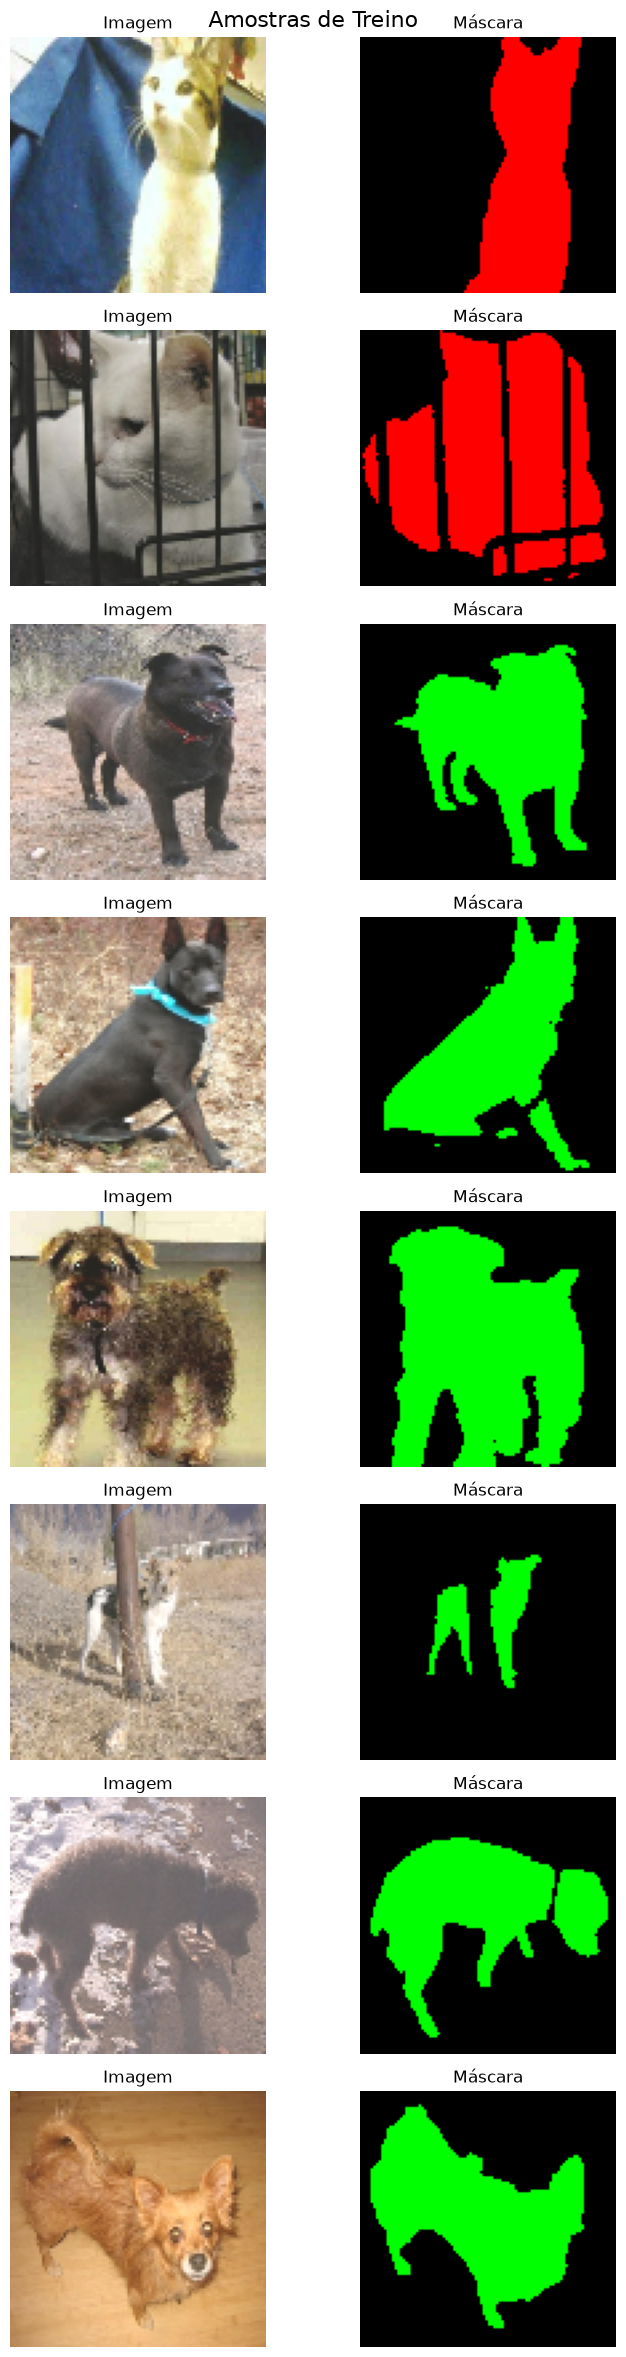

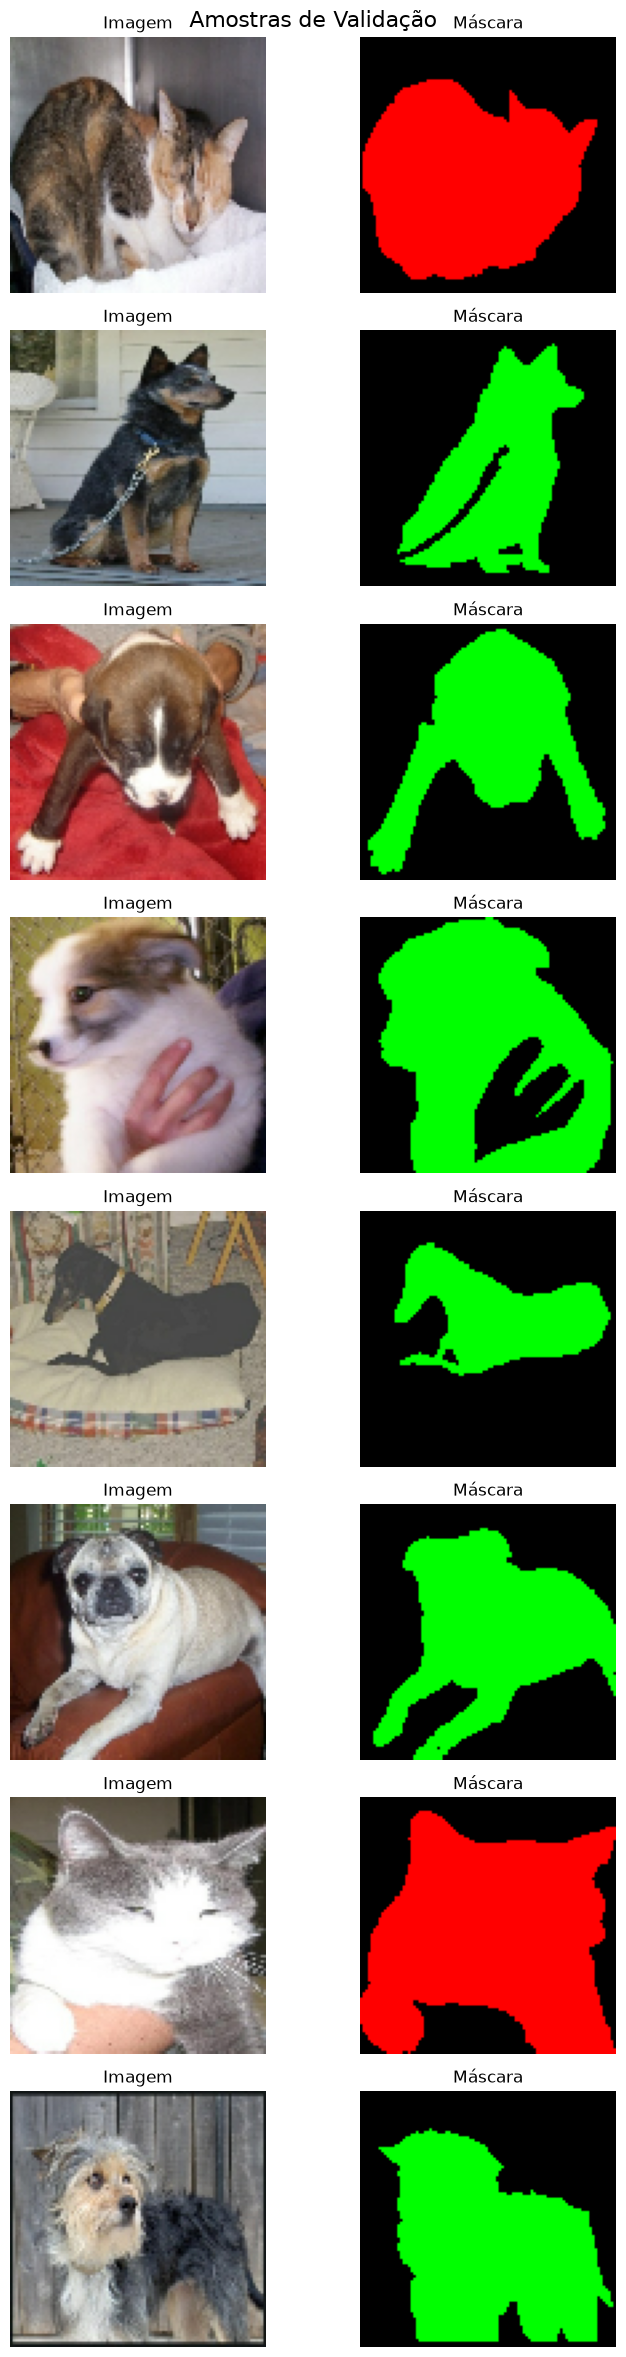

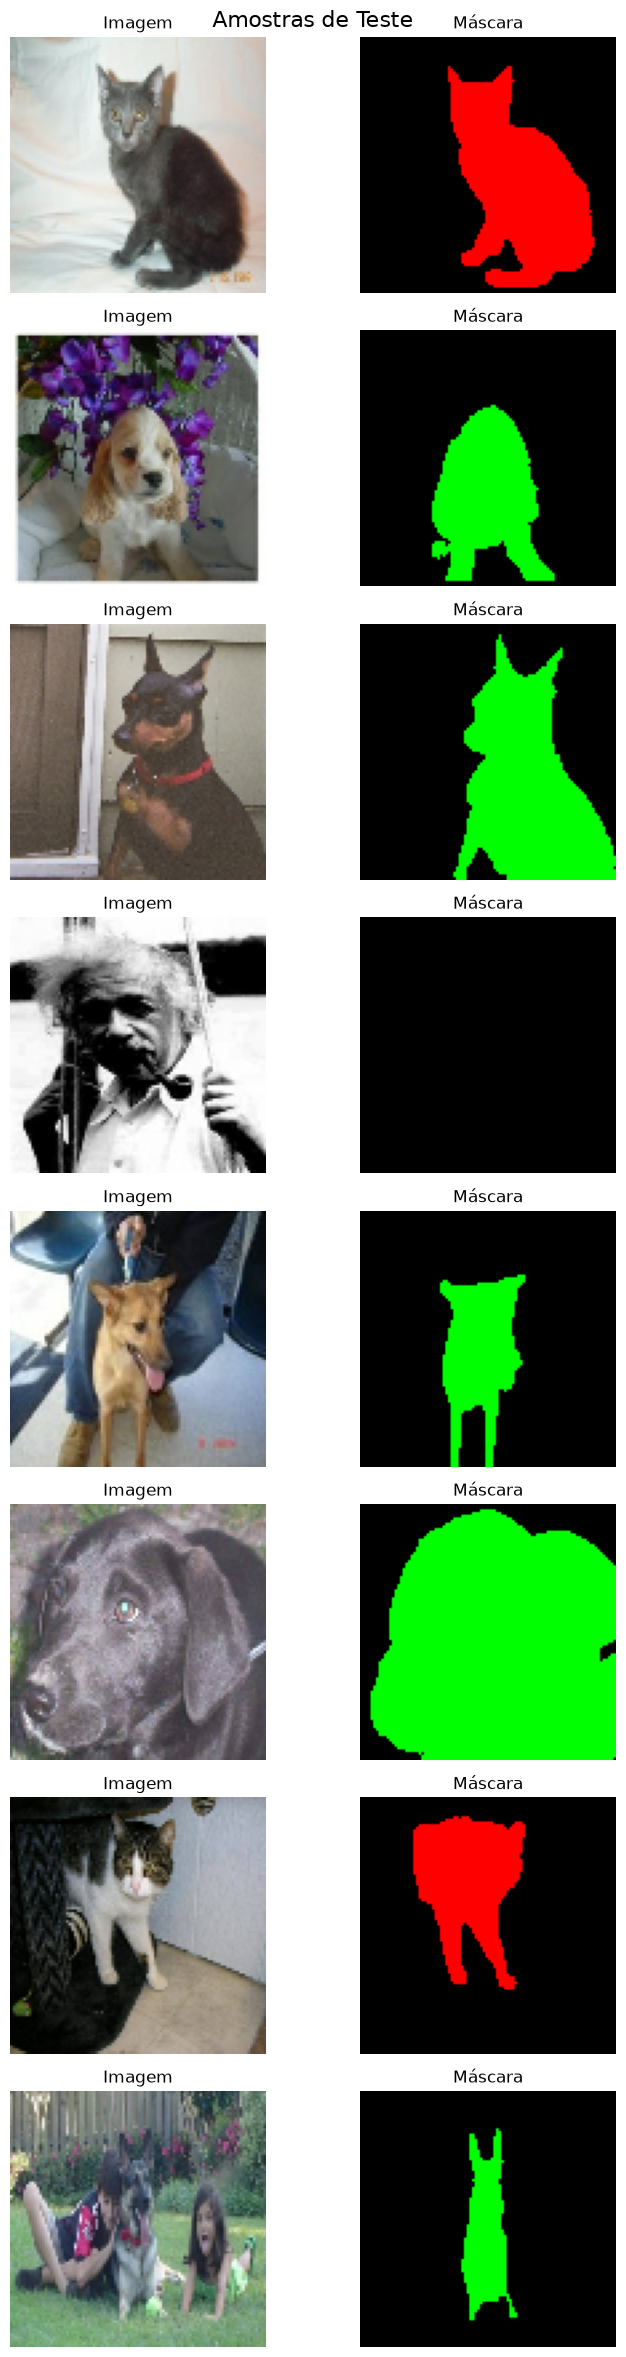

In [9]:
COLOR_MAP = np.array(
    [
        [0, 0, 0],
        [255, 0, 0],
        [0, 255, 0]
    ],
    dtype=np.uint8
)


def plot_dataset_samples(dataset, title, num_images=8):
    imgs, msks = next(iter(dataset.unbatch().batch(num_images)))

    fig, axes = plt.subplots(num_images, 2, figsize=(8, 3 * num_images))
    fig.suptitle(title, fontsize=16)

    if num_images == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_images):
        img = _denormalize_image(imgs[i]).numpy()
        msk = msks[i].numpy().astype(np.int32)
        msk_color = COLOR_MAP[msk]

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Imagem")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(msk_color)
        axes[i, 1].set_title("Máscara")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

plot_dataset_samples(train_ds, "Amostras de Treino", num_images=8)
plot_dataset_samples(val_ds, "Amostras de Validação", num_images=8)
plot_dataset_samples(test_ds, "Amostras de Teste", num_images=8)

# Arquitetura do Modelo e Funções de Perda

In [10]:
from tf_2_0_fast_scnn import build_fast_scnn


In [11]:
def multiclass_dice_loss_tf(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.int32)
    probs = tf.nn.softmax(y_pred, axis=-1)

    total = 0.0

    for c in range(TrainConfig.NUM_CLASSES):
        pred_c = probs[..., c]
        true_c = tf.cast(tf.equal(y_true, c), tf.float32)

        inter = tf.reduce_sum(pred_c * true_c)
        denom = tf.reduce_sum(pred_c) + tf.reduce_sum(true_c)

        total += 1.0 - (2.0 * inter + smooth) / (denom + smooth)

    return total / TrainConfig.NUM_CLASSES


def combined_loss_tf(y_true, y_pred):
    sce = tf.keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred,
        from_logits=True
    )

    return tf.reduce_mean(sce) + multiclass_dice_loss_tf(y_true, y_pred)


def multiclass_iou_tf(y_true, y_pred):
    pred = tf.argmax(y_pred, axis=-1, output_type=tf.int32)
    true = tf.cast(y_true, tf.int32)

    ious = []

    for c in range(TrainConfig.NUM_CLASSES):
        pred_c = tf.equal(pred, c)
        true_c = tf.equal(true, c)

        inter = tf.reduce_sum(tf.cast(pred_c & true_c, tf.float32))
        union = tf.reduce_sum(tf.cast(pred_c | true_c, tf.float32))

        ious.append(tf.math.divide_no_nan(inter, union))

    return tf.reduce_mean(tf.stack(ious))

In [12]:
model = build_fast_scnn(
    num_classes=TrainConfig.NUM_CLASSES,
    input_shape=(*TrainConfig.IMG_SIZE, 3),
    pyramid_bins=(1, 3) ## (1, 2, 5, 10)
)

params_m = model.count_params() / 1e6

print("Params (M):", params_m)
model.summary(line_length=160)

Params (M): 1.204131


Model: "Fast_SCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                                  ┃ Output Shape                           ┃                   Param 
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━
│ input (InputLayer)                            │ (None, 96, 96, 3)                      │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ conv2d (Conv2D)                               │ (None, 48, 48, 32)                     │                       89
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ batch_normalization (BatchNormalization)      │ (None, 48, 48, 32)                     │                       12
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ re_lu (ReLU)                                  │ (None, 48, 48, 32)                     │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ separable_conv2d (SeparableConv2D)            │ (None, 24, 24, 48)                     │                     1,87
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ batch_normalization_1 (BatchNormalization)    │ (None, 24, 24, 48)                     │                       19
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ re_lu_1 (ReLU)                                │ (None, 24, 24, 48)                     │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ separable_conv2d_1 (SeparableConv2D)          │ (None, 12, 12, 64)                     │                     3,56
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ batch_normalization_2 (BatchNormalization)    │ (None, 12, 12, 64)                     │                       25
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ re_lu_2 (ReLU)                                │ (None, 12, 12, 64)                     │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ conv2d_1 (Conv2D)                             │ (None, 12, 12, 384)                    │                    24,96
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ batch_normalization_3 (BatchNormalization)    │ (None, 12, 12, 384)                    │                     1,53
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ re_lu_3 (ReLU)                                │ (None, 12, 12, 384)                    │                         
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ depthwise_conv2d (DepthwiseConv2D)            │ (None, 6, 6, 384)                      │                     3,84
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ batch_normalization_4 (BatchNormalization)    │ (None, 6, 6, 384)                      │                     1,53
├───────────────────────────────────────────────┼────────────────────────────────────────┼─────────────────────────
│ re_lu_4 (ReLU)                                │ (None, 6, 6, 384)                      │                         
├───────────────────────────────────────────────┼───────

 Total params: 1,204,131 (4.59 MB)

 Trainable params: 1,181,123 (4.51 MB)

 Non-trainable params: 23,008 (89.88 KB)

# Treino

In [13]:
# Treino

def warmup_cosine_lr(epoch, _learning_rate):
    if epoch < TrainConfig.WARMUP_EPOCHS:
        return TrainConfig.LR * (epoch + 1) / TrainConfig.WARMUP_EPOCHS

    progress = (epoch - TrainConfig.WARMUP_EPOCHS) / max(
        1,
        TrainConfig.EPOCHS - TrainConfig.WARMUP_EPOCHS
    )

    return TrainConfig.LR * 0.5 * (1.0 + np.cos(np.pi * progress))


optimizer = keras.optimizers.AdamW(
    learning_rate=TrainConfig.LR,
    weight_decay=TrainConfig.WEIGHT_DECAY
)

model.compile(
    optimizer=optimizer,
    loss=combined_loss_tf,
    metrics=[multiclass_iou_tf],
    jit_compile=False
)

ckpt_path = str(Path(TrainConfig.OUT_DIR) / f"best_model_{TrainConfig.VERSION}.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(
        ckpt_path,
        monitor="val_multiclass_iou_tf",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.LearningRateScheduler(
        warmup_cosine_lr,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_multiclass_iou_tf",
        patience=TrainConfig.EARLY_STOP_PATIENCE,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
]

In [14]:
history = model.fit(
    train_ds,
    epochs=TrainConfig.EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks,
    verbose=1
)


Epoch 1: LearningRateScheduler setting learning rate to 0.0002.
Epoch 1/100


/opt/conda/envs/tf218_gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1785604795.877237  122022 meta_optimizer.cc:966] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Fast_SCNN_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1785604798.810146  122637 cuda_dnn.cc:529] Loaded cuDNN version 90300


876/876 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1.2624 - multiclass_iou_tf: 0.4264
Epoch 1: val_multiclass_iou_tf improved from None to 0.48118, saving model to /home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px/best_model_gatos_cachorro_unet_v5_fast_scnn_96px.keras

Epoch 1: finished saving model to /home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px/best_model_gatos_cachorro_unet_v5_fast_scnn_96px.keras
876/876 ━━━━━━━━━━━━━━━━━━━━ 59s 44ms/step - loss: 1.2624 - multiclass_iou_tf: 0.4264 - val_loss: 1.0945 - val_multiclass_iou_tf: 0.4812 - learning_rate: 2.0000e-04

Epoch 2: LearningRateScheduler setting learning rate to 0.0004.
Epoch 2/100
875/876 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1.0711 - multiclass_iou_tf: 0.5131
Epoch 2: val_multiclass_iou_tf improved from 0.48118 to 0.538

# Resultados do Treino

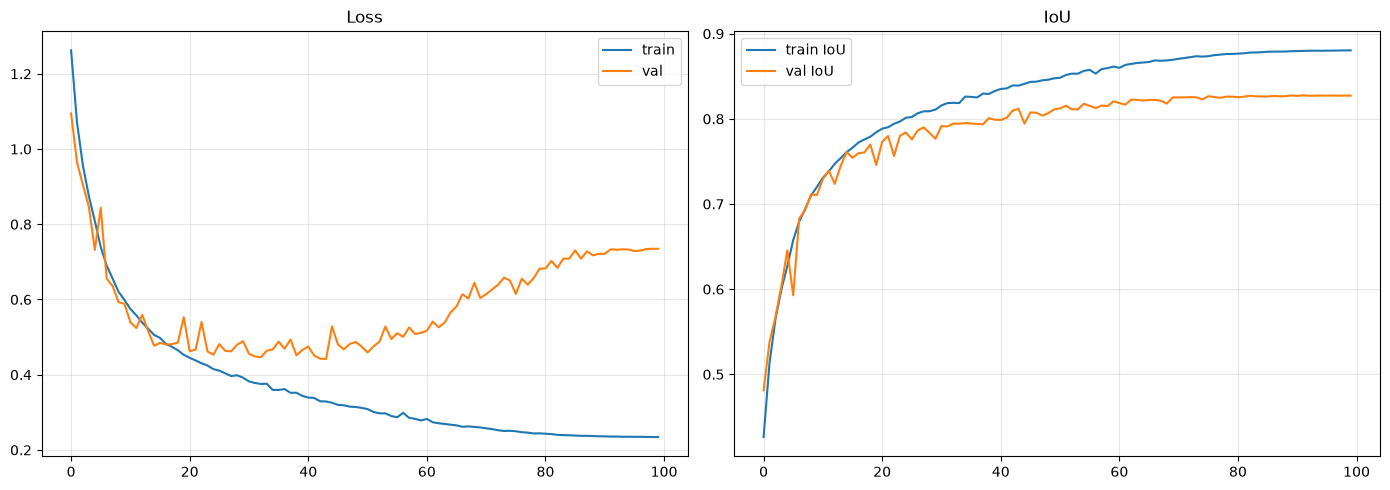

Histórico salvo em: /home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px/training_history_gatos_cachorro_unet_v5_fast_scnn_96px.png


In [15]:
# Resultados do Treino

def plot_history(h, out_dir, version):
    hist = h.history

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist["loss"], label="train")
    axes[0].plot(hist["val_loss"], label="val")
    axes[0].set_title("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    key = "multiclass_iou_tf"
    val_key = f"val_{key}"

    if key in hist and val_key in hist:
        axes[1].plot(hist[key], label="train IoU")
        axes[1].plot(hist[val_key], label="val IoU")

    axes[1].set_title("IoU")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    path = Path(out_dir) / f"training_history_{version}.png"

    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()

    print("Histórico salvo em:", path)


plot_history(history, TrainConfig.OUT_DIR, TrainConfig.VERSION)

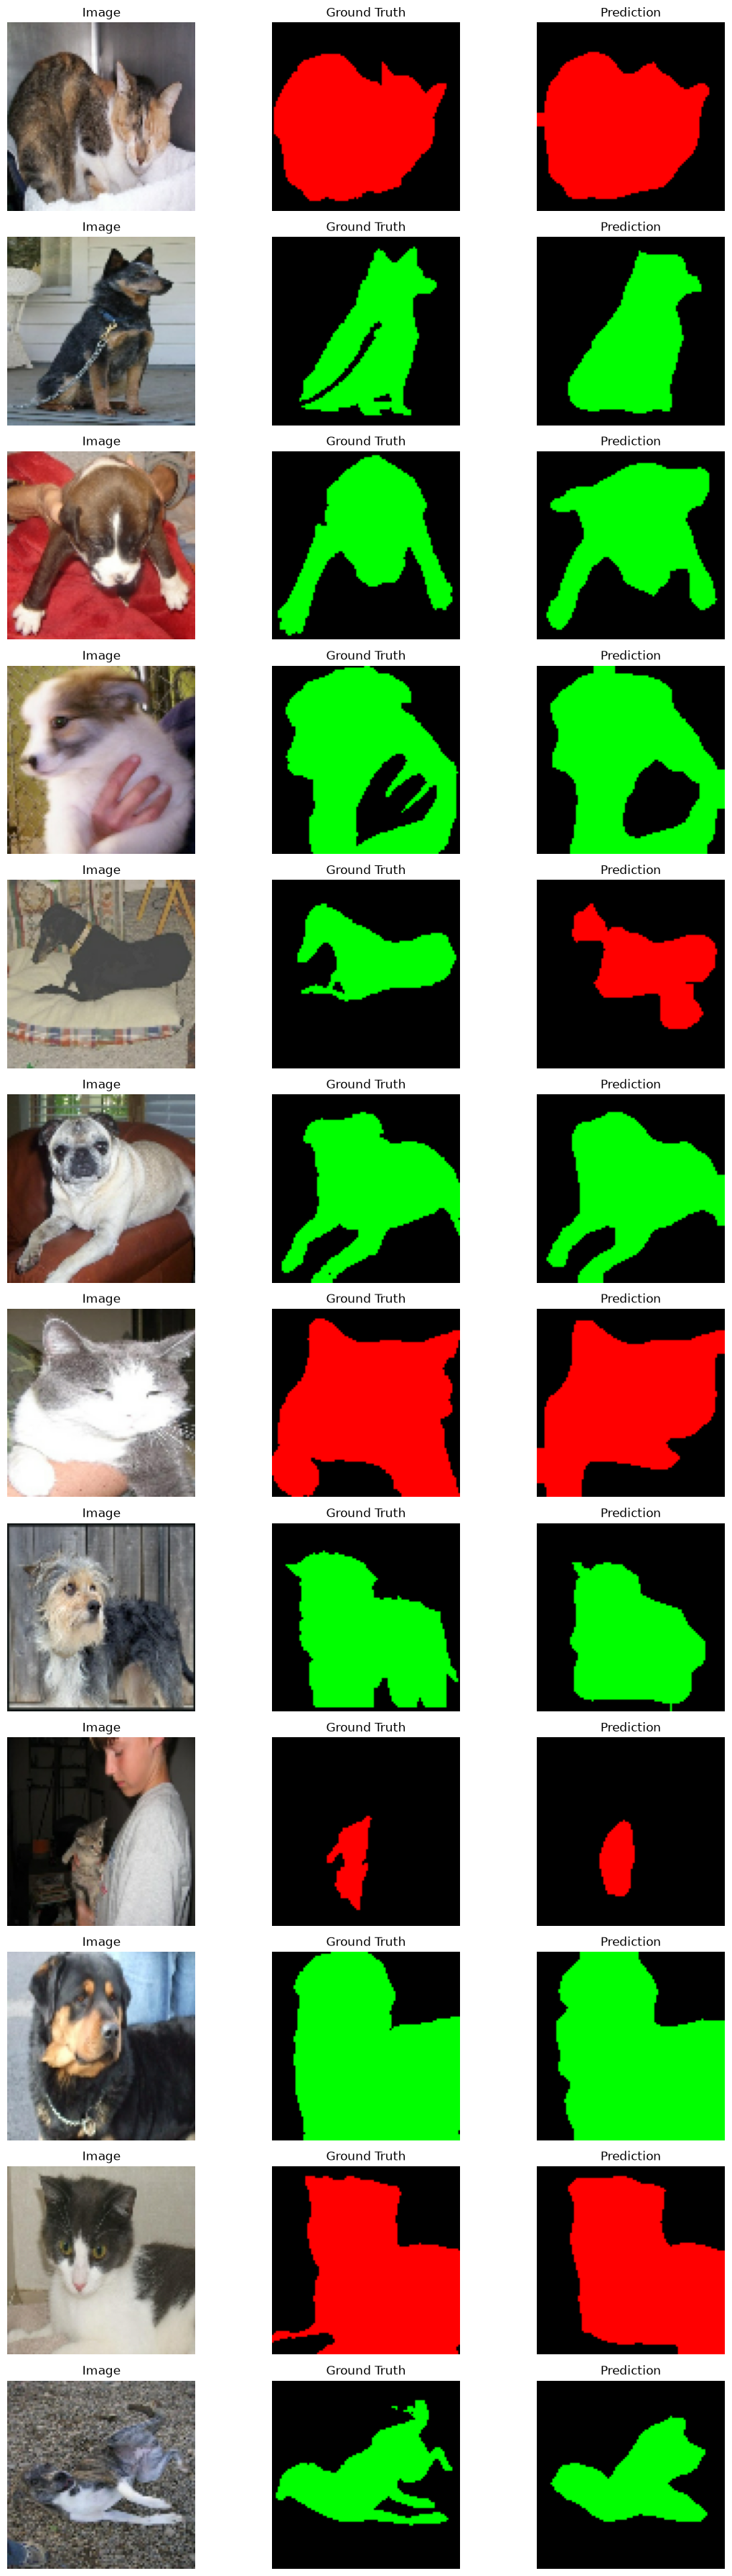

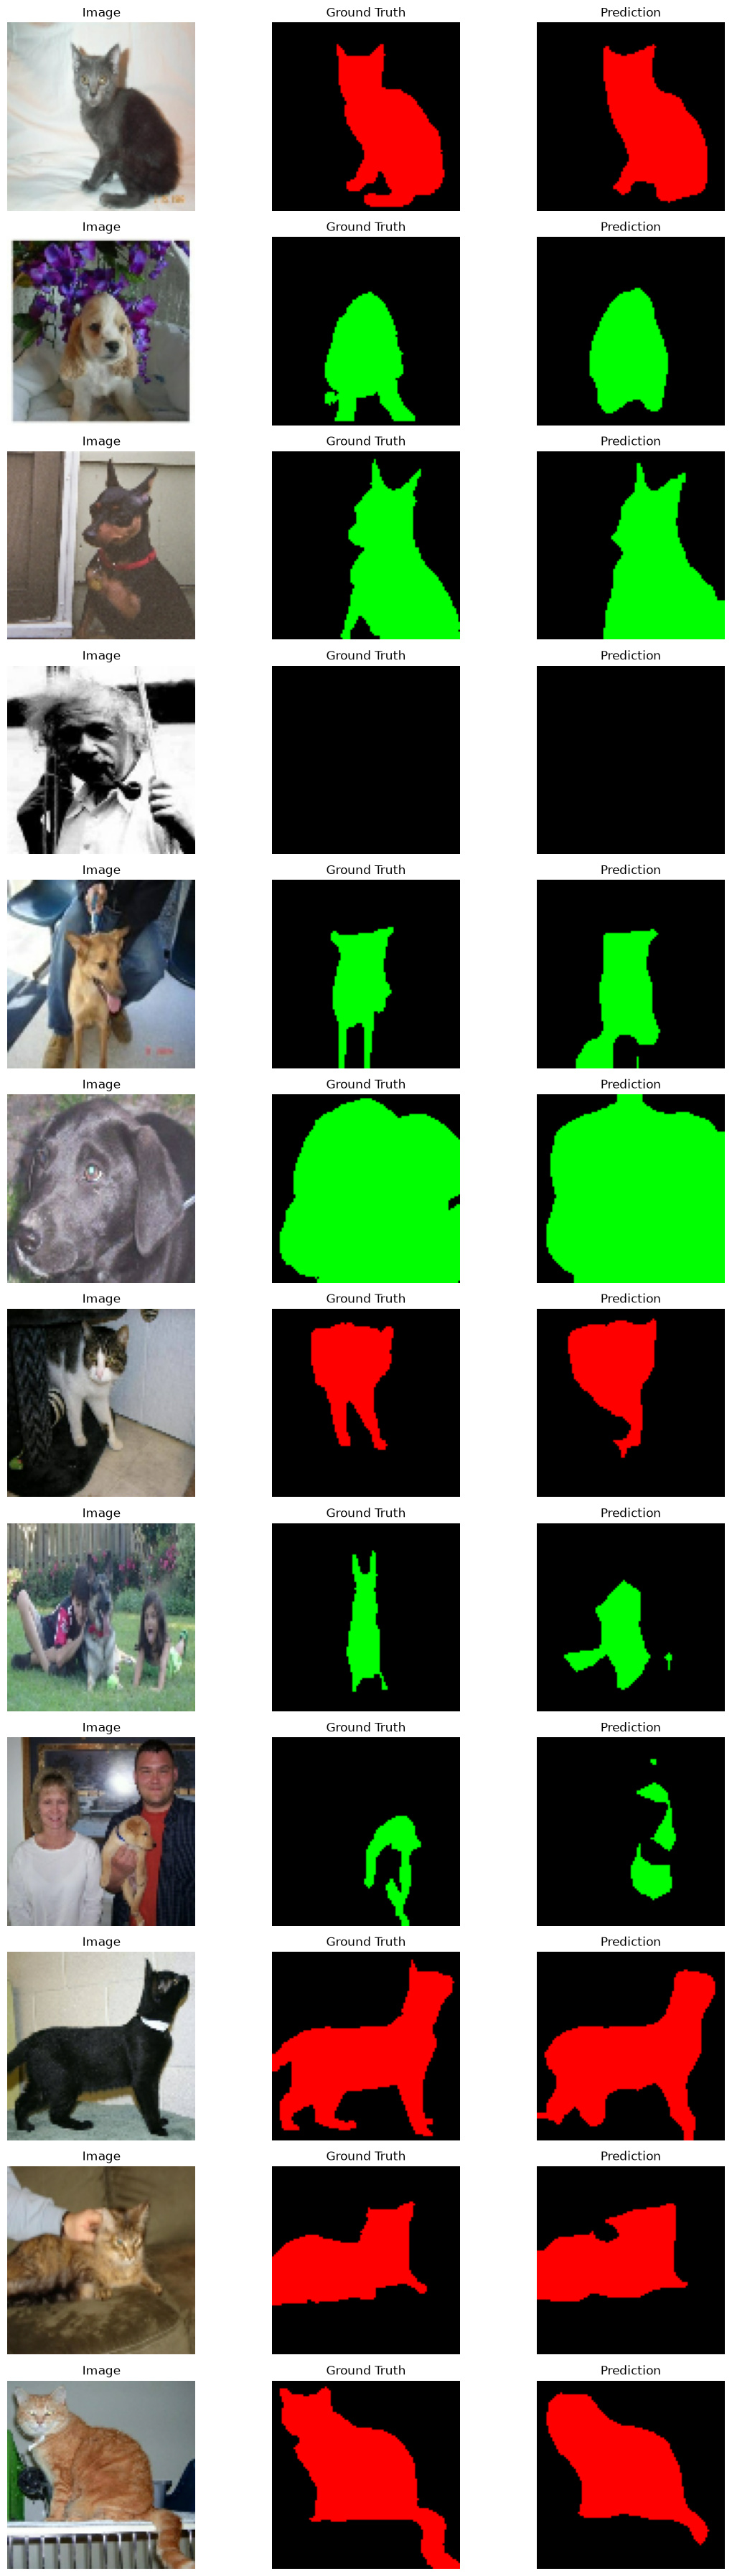

In [16]:
COLOR_MAP = np.array(
    [
        [0, 0, 0],
        [255, 0, 0],
        [0, 255, 0]
    ],
    dtype=np.uint8
)


def visualize_predictions(model, dataset, num_images=12, save_path=None):
    imgs, msks = next(iter(dataset.unbatch().batch(num_images)))

    logits = model.predict(imgs, verbose=0)
    preds = np.argmax(logits, axis=-1).astype(np.int32)

    fig, axes = plt.subplots(num_images, 3, figsize=(12, 3 * num_images))

    if num_images == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_images):
        img = _denormalize_image(imgs[i]).numpy()
        gt = COLOR_MAP[msks[i].numpy().astype(np.int32)]
        pr = COLOR_MAP[preds[i]]

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(gt)
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pr)
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=130)

    plt.show()


viz_path = str(Path(TrainConfig.OUT_DIR) / f"viz_val_{TrainConfig.VERSION}.png")
visualize_predictions(model, val_ds, save_path=viz_path)
viz_path = str(Path(TrainConfig.OUT_DIR) / f"viz_test_{TrainConfig.VERSION}.png")
visualize_predictions(model, test_ds, save_path=viz_path)

In [17]:
results = model.evaluate(test_ds, verbose=1)

test_loss = results[0]
test_iou = results[1]

print(f"Test Loss: {test_loss:.4f}")
print(f"Test IoU: {test_iou:.4f}")

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.7668 - multiclass_iou_tf: 0.8267
Test Loss: 0.7668
Test IoU: 0.8267


# Exportação para ONNX

In [18]:
# Exportação para ONNX

import tf2onnx
import onnx
import onnxruntime as ort

from onnxruntime.quantization import quantize_dynamic, QuantType

OUT_DIR = Path(TrainConfig.OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

infer_model = keras.Model(
    inputs=model.input,
    outputs=model.output,
    name="Fast_SCNN_Infer"
)

onnx_path = OUT_DIR / f"{TrainConfig.VERSION}_infer.onnx"

input_signature = [
    tf.TensorSpec(
        shape=(None, TrainConfig.IMG_SIZE[0], TrainConfig.IMG_SIZE[1], 3),
        dtype=tf.float32,
        name="input"
    )
]

model_proto, _ = tf2onnx.convert.from_keras(
    infer_model,
    input_signature=input_signature,
    opset=13,
    output_path=str(onnx_path)
)

print("ONNX salvo em:", onnx_path)

I0000 00:00:1785608312.559724  122022 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1785608312.559891  122022 single_machine.cc:361] Starting new session
I0000 00:00:1785608312.573584  122022 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78764 MB memory:  -> device: 0, name: NVIDIA H100 80GB HBM3, pci bus id: 0000:61:00.0, compute capability: 9.0
I0000 00:00:1785608313.076595  122022 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 78764 MB memory:  -> device: 0, name: NVIDIA H100 80GB HBM3, pci bus id: 0000:61:00.0, compute capability: 9.0
I0000 00:00:1785608313.157761  122022 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00:1785608313.157978  122022 single_machine.cc:361] Starting new session
I0000 00:00:1785608313.163397  122022 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 

ONNX salvo em: /home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px_infer.onnx


In [19]:
onnx_model = onnx.load(str(onnx_path))
onnx.checker.check_model(onnx_model)

print("ONNX válido:", onnx_path)

ONNX válido: /home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px_infer.onnx


In [20]:
def multiclass_iou_np(pred, gt, num_classes=3):
    ious = []

    for c in range(num_classes):
        pred_c = pred == c
        gt_c = gt == c

        inter = np.logical_and(pred_c, gt_c).sum()
        union = np.logical_or(pred_c, gt_c).sum()

        if union > 0:
            ious.append(inter / union)

    return np.mean(ious) if ious else 0.0


def evaluate_onnx(model_path, dataset):
    session = ort.InferenceSession(
        str(model_path),
        providers=["CPUExecutionProvider"]
    )

    input_name = session.get_inputs()[0].name
    ious = []

    for imgs, msks in dataset:
        logits = session.run(None, {input_name: imgs.numpy().astype(np.float32)})[0]
        preds = np.argmax(logits, axis=-1).astype(np.int32)

        for pred, gt in zip(preds, msks.numpy().astype(np.int32)):
            ious.append(multiclass_iou_np(pred, gt, TrainConfig.NUM_CLASSES))

    mean_iou = np.mean(ious)

    print(f"ONNX Test IoU: {mean_iou:.4f}")

    return mean_iou


onnx_test_iou = evaluate_onnx(onnx_path, test_ds)

ONNX Test IoU: 0.8347


In [21]:
int8_onnx_path = OUT_DIR / f"{TrainConfig.VERSION}_infer_int8_dynamic.onnx"

quantize_dynamic(
    model_input=str(onnx_path),
    model_output=str(int8_onnx_path),
    weight_type=QuantType.QUInt8,
    op_types_to_quantize=["Conv", "MatMul"]
)

print("ONNX INT8 salvo em:", int8_onnx_path)

ONNX INT8 salvo em: /home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px_infer_int8_dynamic.onnx


In [22]:
onnx_int8_test_iou = evaluate_onnx(int8_onnx_path, test_ds)

ONNX Test IoU: 0.8339


#  Tensorflow Lite

In [23]:
# Tensorflow Lite

from pathlib import Path
import numpy as np
import tensorflow as tf
from tqdm import tqdm
import matplotlib.pyplot as plt

OUT_DIR = Path(TrainConfig.OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

infer_model_logits = tf.keras.Model(
    inputs=model.input,
    outputs=model.output,
    name="Fast_SCNN_Infer_Logits"
)

print("Modelo Logits | Saída:", infer_model_logits.output_shape)

Modelo Logits | Saída: (None, 96, 96, 3)


In [24]:
tflite_fp32_path = OUT_DIR / f"model_{TrainConfig.VERSION}_infer_fp32.tflite"

converter_fp32 = tf.lite.TFLiteConverter.from_keras_model(infer_model_logits)
tflite_model_fp32 = converter_fp32.convert()

tflite_fp32_path.write_bytes(tflite_model_fp32)

print(f"Modelo FP32 salvo em: {tflite_fp32_path}")
print(f"Tamanho: {tflite_fp32_path.stat().st_size / 1024:.2f} KB")

Saved artifact at '/tmp/tmpdqxc7f86'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='input')
Output Type:
  TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name=None)
Captures:
  137218621619280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137218621619088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186251408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186249872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137218621618512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186250448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186251216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186249680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186249488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186251984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186252560

W0000 00:00:1785608341.219351  122022 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1785608341.219389  122022 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1785608341.322384  122022 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled


In [25]:
N_REP = 20

def representative_dataset_gen():
    for img_tensor, _ in tqdm(
        val_ds.unbatch().batch(1).take(N_REP),
        total=N_REP,
        desc="Rep-dataset"
    ):
        yield [tf.cast(img_tensor, tf.float32)]

In [26]:
tflite_int8_path = OUT_DIR / f"model_{TrainConfig.VERSION}_infer_int8_full.tflite"

converter_int8 = tf.lite.TFLiteConverter.from_keras_model(infer_model_logits)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset_gen
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8
converter_int8._experimental_new_quantizer = True

tflite_model_int8 = converter_int8.convert()
tflite_int8_path.write_bytes(tflite_model_int8)

print(f"Modelo Full INT8 salvo em: {tflite_int8_path}")
print(f"Tamanho: {tflite_int8_path.stat().st_size / 1024:.2f} KB")

Saved artifact at '/tmp/tmpa9k0cvcz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='input')
Output Type:
  TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name=None)
Captures:
  137218621619280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137218621619088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186251408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186249872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137218621618512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186250448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186251216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186249680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186249488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186251984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137224186252560

/opt/conda/envs/tf218_gpu/lib/python3.11/site-packages/tensorflow/lite/python/convert.py:997: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1785608347.597990  122022 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1785608347.598023  122022 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
Rep-dataset: 100%|██████████| 20/20 [00:00<00:00, 50.24it/s]
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


Modelo Full INT8 salvo em: /home/jovyan/privado/wolosky_notebooks/tensorflow/u2net/gatos_cachorro_unet/gatos_cachorro_unet_v5_fast_scnn_96px/gatos_cachorro_unet_v5_fast_scnn_96px/model_gatos_cachorro_unet_v5_fast_scnn_96px_infer_int8_full.tflite
Tamanho: 1491.99 KB


In [27]:
def ensure_input_shape(interpreter, image_tensor):
    shape = image_tensor.shape

    if len(shape) == 3:
        b, h, w, c = 1, int(shape[0]), int(shape[1]), int(shape[2])
    elif len(shape) == 4:
        b, h, w, c = int(shape[0]), int(shape[1]), int(shape[2]), int(shape[3])
    else:
        raise ValueError(f"shape inválido: {shape}")

    input_details = interpreter.get_input_details()[0]
    current_shape = input_details["shape"]

    if (
        current_shape[0] != b
        or current_shape[1] != h
        or current_shape[2] != w
        or current_shape[3] != c
    ):
        interpreter.resize_tensor_input(input_details["index"], [b, h, w, c])
        interpreter.allocate_tensors()


def run_tflite_fp32(interpreter, image_tensor):
    ensure_input_shape(interpreter, image_tensor)

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    interpreter.set_tensor(input_details["index"], image_tensor.numpy().astype(np.float32))
    interpreter.invoke()

    logits = interpreter.get_tensor(output_details["index"])

    return np.argmax(logits, axis=-1).astype(np.int32)


def run_tflite_int8(interpreter, image_tensor):
    ensure_input_shape(interpreter, image_tensor)

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    input_scale, input_zero_point = input_details["quantization"]
    output_scale, output_zero_point = output_details["quantization"]

    image_int8 = np.round(image_tensor.numpy() / input_scale + input_zero_point)
    image_int8 = np.clip(image_int8, -128, 127).astype(np.int8)

    interpreter.set_tensor(input_details["index"], image_int8)
    interpreter.invoke()

    output_int8 = interpreter.get_tensor(output_details["index"])
    logits = (output_int8.astype(np.float32) - output_zero_point) * output_scale

    return np.argmax(logits, axis=-1).astype(np.int32)

def multiclass_iou_np(pred, gt, num_classes=3):
    ious = []

    for c in range(num_classes):
        pred_c = pred == c
        gt_c = gt == c

        inter = np.logical_and(pred_c, gt_c).sum()
        union = np.logical_or(pred_c, gt_c).sum()

        if union > 0:
            ious.append(inter / union)

    return np.mean(ious) if ious else 0.0


def evaluate_tflite_model(model_path, inference_fn, model_type, dataset, num_images=8):
    interpreter = tf.lite.Interpreter(model_path=str(model_path))
    interpreter.allocate_tensors()

    ious = []

    for img, mask in tqdm(dataset.unbatch(), desc=f"Inferindo {model_type}", total=len(test_idx)):
        pred = inference_fn(interpreter, img[None, ...]).squeeze()
        gt = mask.numpy().astype(np.int32)

        ious.append(multiclass_iou_np(pred, gt, TrainConfig.NUM_CLASSES))

    mean_iou = np.mean(ious)

    print(f"IoU {model_type}: {mean_iou:.4f}")

    fig = plt.figure(figsize=(12, num_images * 3))
    fig.suptitle(f"TFLite {model_type} | IoU: {mean_iou:.4f}", fontsize=16)

    for k, (img, mask) in enumerate(dataset.unbatch().take(num_images)):
        pred = inference_fn(interpreter, img[None, ...]).squeeze()

        axes_img = plt.subplot(num_images, 3, 3 * k + 1)
        axes_img.imshow(_denormalize_image(img).numpy())
        axes_img.axis("off")
        axes_img.set_title("Imagem")

        axes_gt = plt.subplot(num_images, 3, 3 * k + 2)
        axes_gt.imshow(COLOR_MAP[mask.numpy().astype(np.int32)])
        axes_gt.axis("off")
        axes_gt.set_title("Ground Truth")

        axes_pr = plt.subplot(num_images, 3, 3 * k + 3)
        axes_pr.imshow(COLOR_MAP[pred.astype(np.int32)])
        axes_pr.axis("off")
        axes_pr.set_title("Predição")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    viz_path = OUT_DIR / f"viz_test_TFLITE_{model_type}_{TrainConfig.VERSION}.png"
    plt.savefig(viz_path, dpi=130)
    plt.show()

    return mean_iou

/opt/conda/envs/tf218_gpu/lib/python3.11/site-packages/tensorflow/lite/python/interpreter.py:451: UserWarning:     Warning: Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
Inferindo FP32: 100%|██████████| 3503/3503 [00:08<00:00, 393.58it/s]


IoU FP32: 0.8347


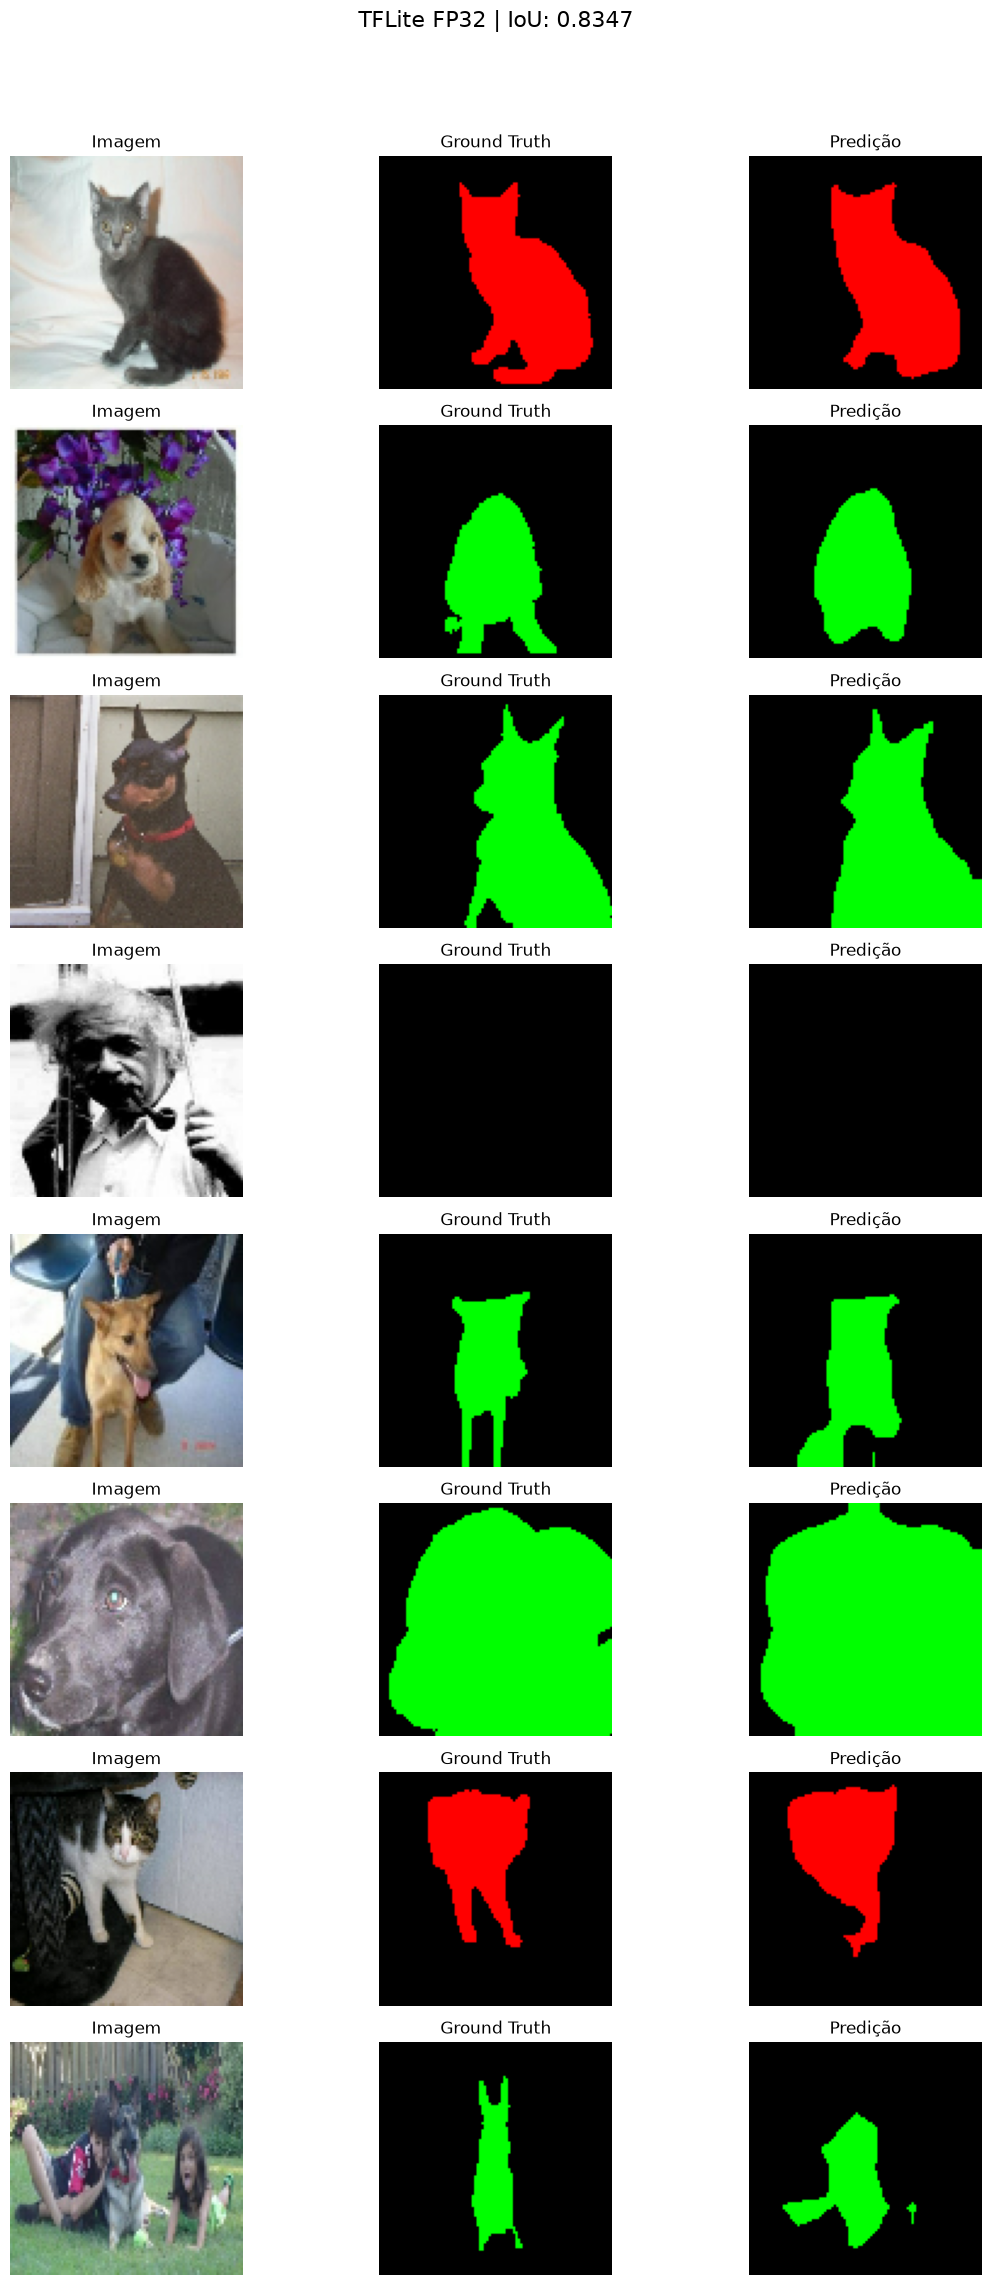

In [28]:
tflite_fp32_iou = evaluate_tflite_model(
    tflite_fp32_path,
    run_tflite_fp32,
    "FP32",
    test_ds
)

Inferindo INT8: 100%|██████████| 3503/3503 [00:06<00:00, 536.31it/s]


IoU INT8: 0.8207


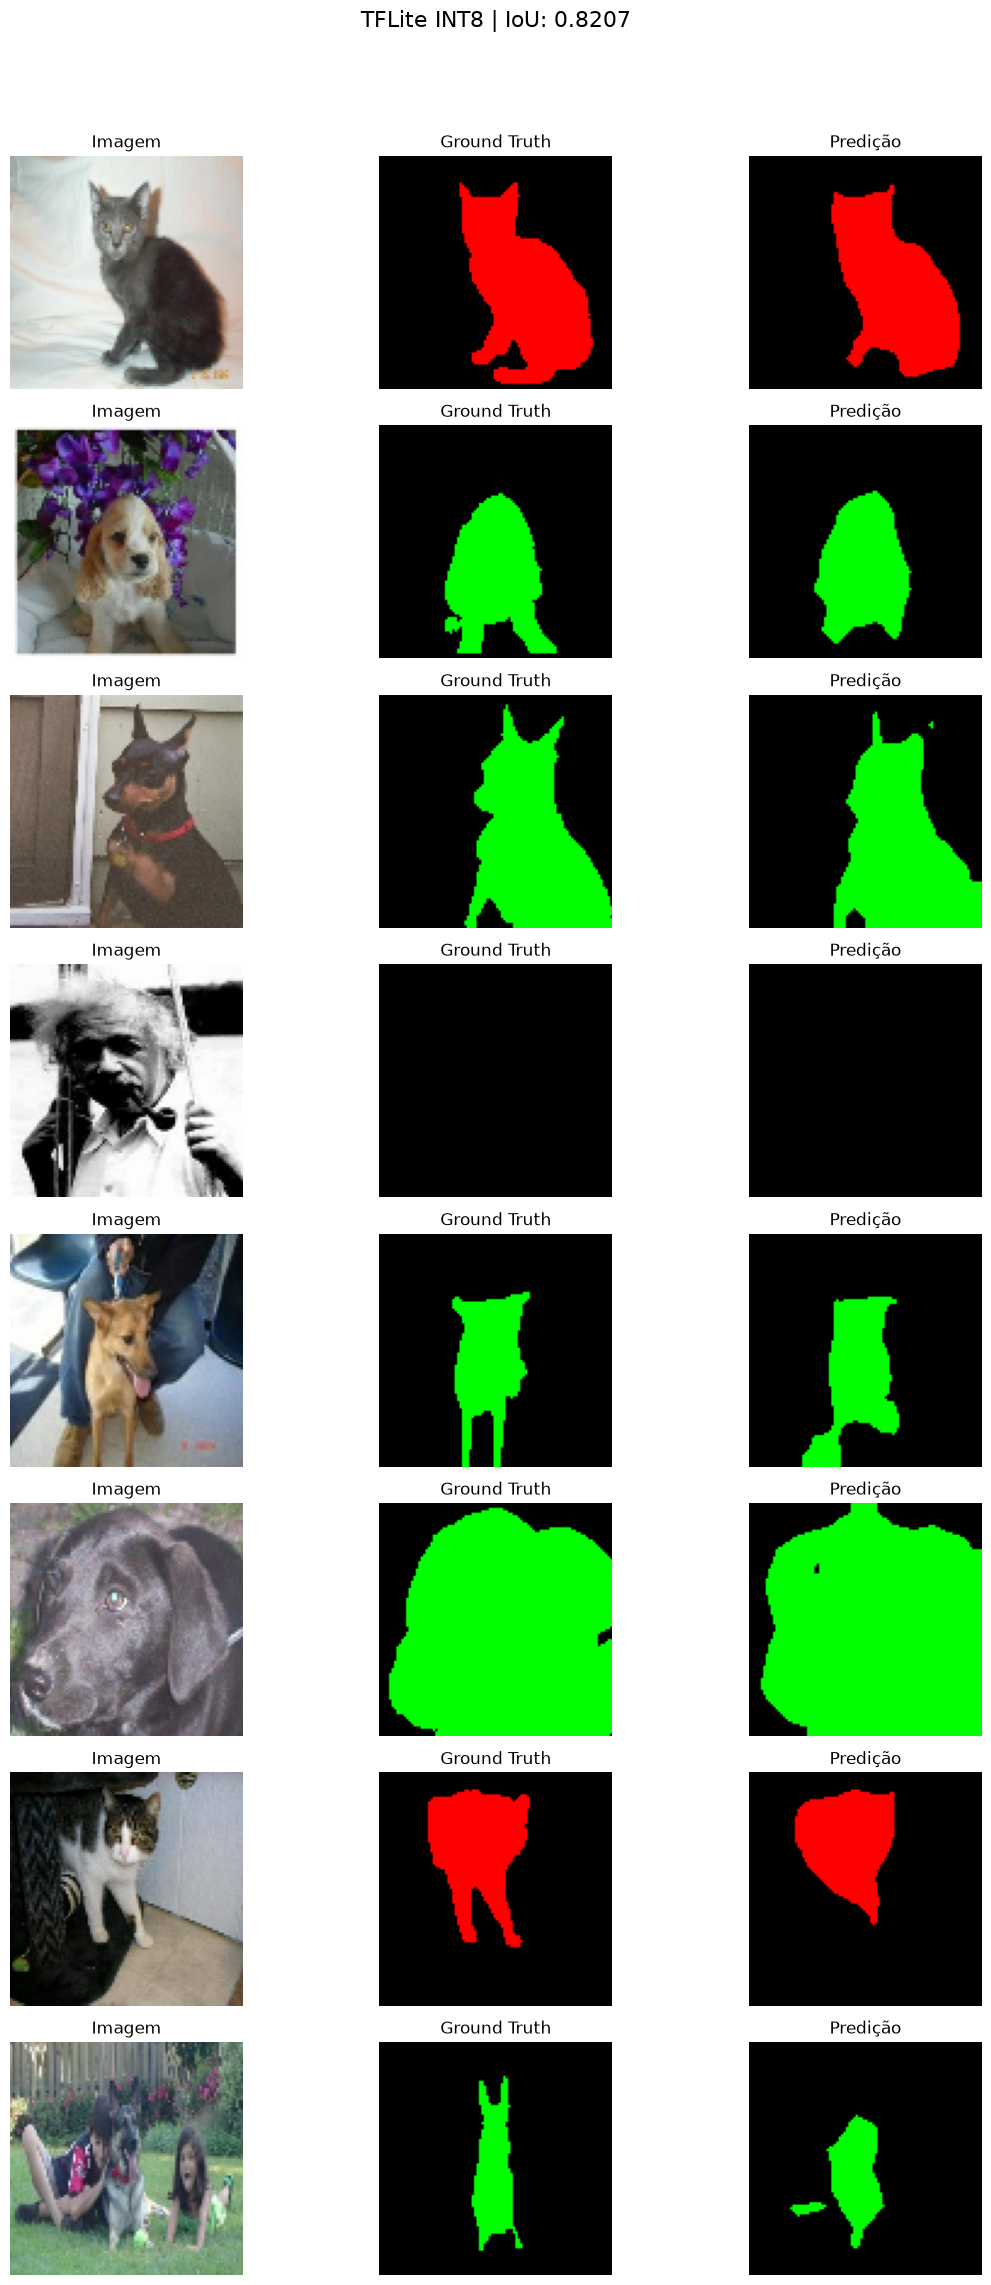

In [29]:
# Avalia o modelo Full INT8
tflite_int8_iou = evaluate_tflite_model(
    tflite_int8_path,
    run_tflite_int8,
    "INT8",
    test_ds
)